# Check which layer has the stongest submesoscale heat flux

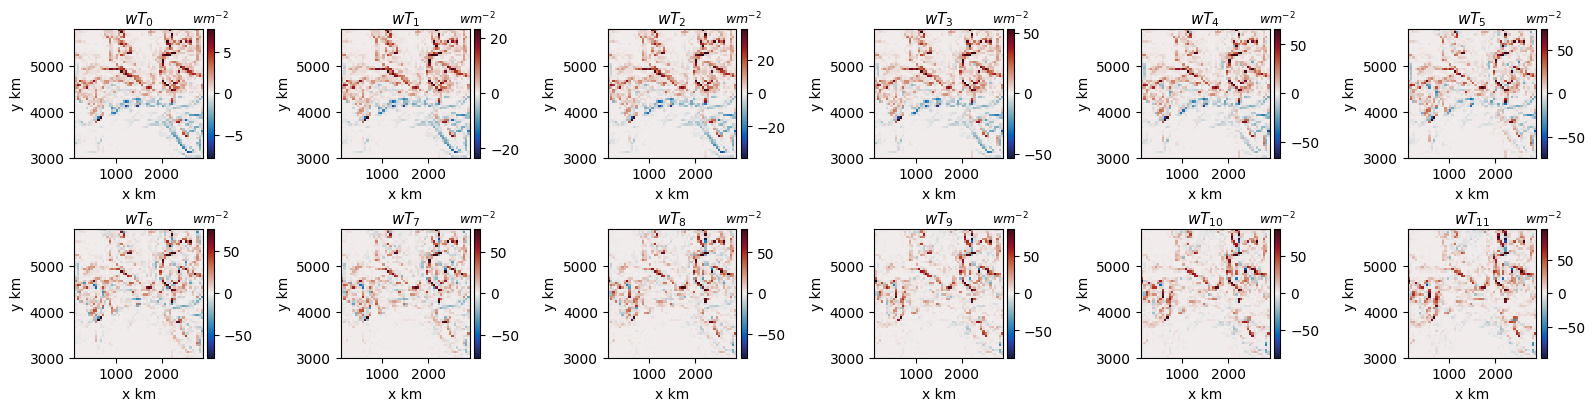

In [16]:
# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import data_loader

from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf
import importlib
from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_MITgcm
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=10, box_i=10)
XC_c = ds_coarse["XC"]
YC_c = ds_coarse["YC"]

# load the nc data
ds = xr.open_dataset("../../data_5km/save_coarse/13901616_nc/wT_sub_12h_blocks.nc", engine="h5netcdf")
wT = ds["wT_sub_kC"]

# limits function
def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# position
t = -1
x1, x2 = 60,  116
y1, y2 = 2, 58

# plot 
fields = {
    r"$wT_0$":         {"Z": wT[t,0, 30:86, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_1$":         {"Z": wT[t,1, 30:86, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_2$":         {"Z": wT[t,2, 30:86, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_3$":         {"Z": wT[t,3, 30:86, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_4$":         {"Z": wT[t,4, 30:86, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_5$":         {"Z": wT[t,5, 30:86, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_6$":         {"Z": wT[t,6, 30:86, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_7$":         {"Z": wT[t,7, 30:86, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_8$":         {"Z": wT[t,8, 30:86, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_9$":         {"Z": wT[t,9, 30:86, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_{10}$":         {"Z": wT[t,10, 30:86, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_{11}$":         {"Z": wT[t,11, 30:86, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
}     

# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None

# Plot: 2×5
fig, axes = plt.subplots(2,6, figsize=(16, 4), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    norm = meta["norm"]
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX[:, :], YY[:, :], Z[:, :], shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
fig.savefig("./heatflux_layers.png")
plt.show()

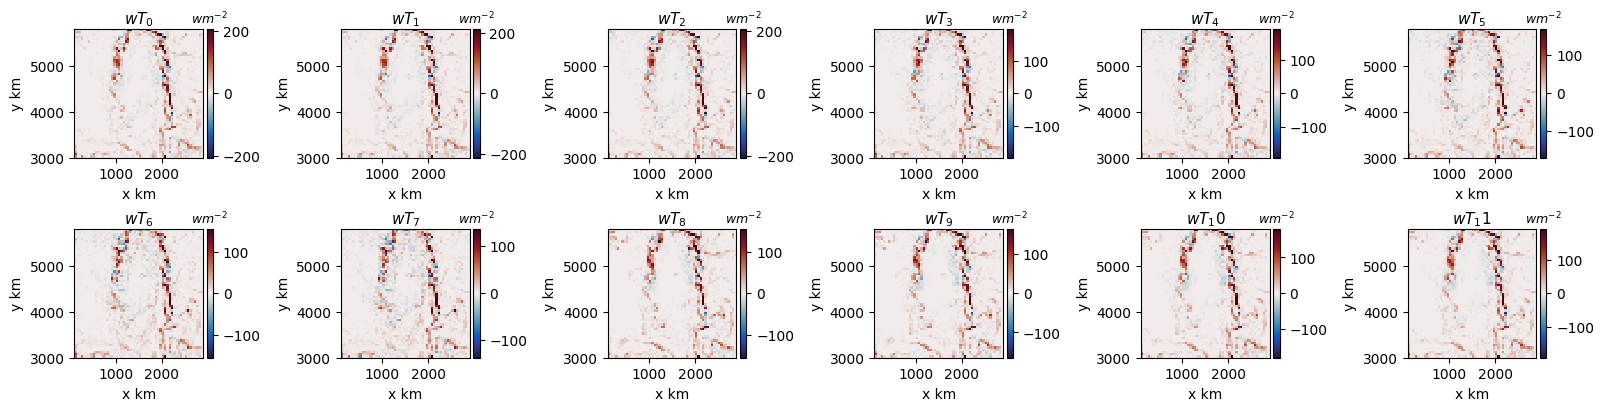

In [38]:
# compare the npz data with data after data_loader

# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import data_loader

from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf
import importlib
from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_MITgcm
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=10, box_i=10)
XC_c = ds_coarse["XC"]
YC_c = ds_coarse["YC"]

# load the nc data
ds = xr.open_dataset("../../data_5km/save_coarse/13901616_nc/wT_sub_12h_blocks.nc", engine="h5netcdf")
wT = ds["wT_sub_kC"]

# limits function
def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# position
t = -1
x1, x2 = 60,  116
y1, y2 = 2, 58

# plot 
fields = {
    r"$wT_0$":         {"Z": wT[t,12, 62:118, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_1$":         {"Z": wT[t,13, 62:118, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_2$":         {"Z": wT[t,14, 62:118, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_3$":         {"Z": wT[t,15, 62:118, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_4$":         {"Z": wT[t,16, 62:118, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_5$":         {"Z": wT[t,17, 62:118, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_6$":         {"Z": wT[t,18, 62:118, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_7$":         {"Z": wT[t,19, 62:118, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_8$":         {"Z": wT[t,8, 62:118, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_9$":         {"Z": wT[t,9, 62:118, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_10$":         {"Z": wT[t,10, 62:118, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_11$":         {"Z": wT[t,11, 62:118, 1:57],  "units": r"$w m^{-2}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
}     

# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None

# Plot: 2×5
fig, axes = plt.subplots(2,6, figsize=(16, 4), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    norm = meta["norm"]
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX[:, :], YY[:, :], Z[:, :], shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
fig.savefig("./heatflux_layers_2.png")
plt.show()

# Check nc and npz file consistence

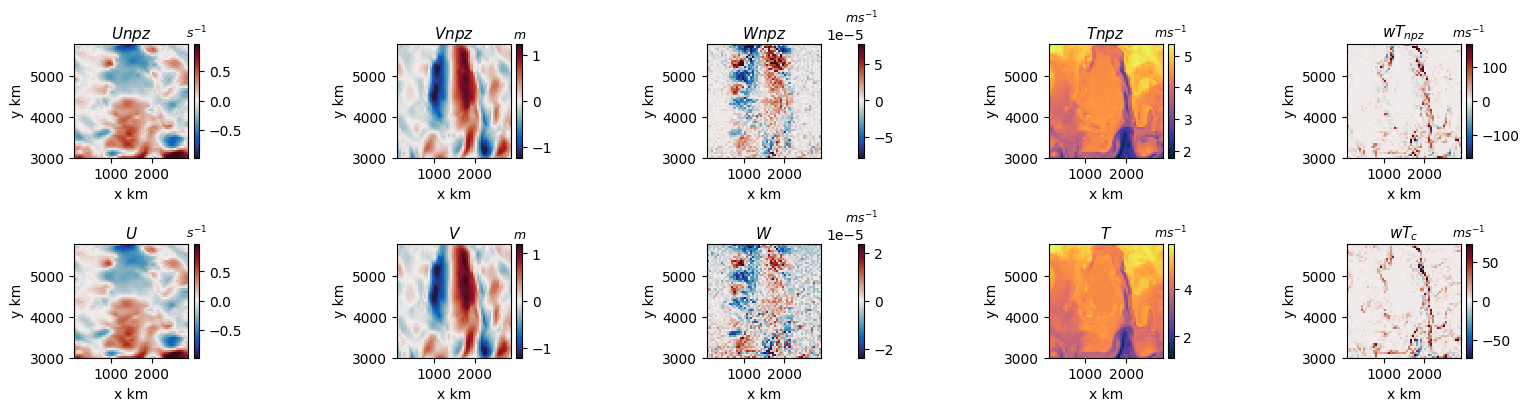

In [3]:
# compare the npz data with data after data_loader

# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils.machine_learning import data_loader

from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf
import importlib
from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_MITgcm
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=10, box_i=10)
XC_c = ds_coarse["XC"]
YC_c = ds_coarse["YC"]

# load nc file
ds = xr.open_dataset("/scratch/jczhang/data_5km/save_coarse/13901616_nc/wT_sub_12h_blocks.nc", engine="h5netcdf")
wT = ds["wT_sub_kC"]
ds = xr.open_dataset("/scratch/jczhang/data_5km/save_coarse/13901616_nc/U_12hmean_coarse.nc", engine="h5netcdf")
U = ds["U"]
ds = xr.open_dataset("/scratch/jczhang/data_5km/save_coarse/13901616_nc/V_12hmean_coarse.nc", engine="h5netcdf")
V = ds["V"]
ds = xr.open_dataset("/scratch/jczhang/data_5km/save_coarse/13901616_nc/W_12hmean_coarse.nc", engine="h5netcdf")
W = ds["W"]
ds = xr.open_dataset("/scratch/jczhang/data_5km/save_coarse/13901616_nc/T_12hmean_coarse.nc", engine="h5netcdf")
T = ds["T"]


# limits function
def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# load the npz data
fn = "/scratch/jczhang/submeso_data_driven/data/mld/zeta.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    zeta_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/submeso_data_driven/data/mld/U.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    U_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/submeso_data_driven/data/mld/V.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    V_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/submeso_data_driven/data/mld/W.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    W_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/submeso_data_driven/data/mld/speed.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    speed_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/submeso_data_driven/data/mld/strain.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    strain_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/submeso_data_driven/data/mld/T.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    T_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/submeso_data_driven/data/mld/wT.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)        # (Nt,)
    wT_npz = npz["data"].astype(np.float32)       # (Nt, j, i)

# position
pos = -1
x1, x2 = 60,  116
y1, y2 = 2, 58
dx = 30
k = 12
# plot 
fields = {
    r"$U{npz}$":         {"Z": U[pos,k,62:118, 2:58],  "units": r"$s^{-1}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$V{npz}$":         {"Z": V[pos,k, 62:118, 2:58],  "units": r"$m$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$W{npz}$":         {"Z": W[pos,k, 62:118, 2:58],  "units": r"$m s^{-1}$",  "kind": "positive", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$T{npz}$":         {"Z": T[pos,k,62:118, 2:58],  "units": r"$m s^{-1}$",  "kind": "seq", "cmap":cmo.thermal, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_{npz}$":         {"Z": wT[pos,k,62:118, 2:58],  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    
    r"$U$":         {"Z": U_npz[pos,:,:],  "units": r"$s^{-1}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$V$":         {"Z": V_npz[pos,:,:],  "units": r"$m$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$W$":         {"Z": W_npz[pos,:,:],  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$T$":         {"Z": T_npz[pos,:,:],  "units": r"$m s^{-1}$",  "kind": "seq", "cmap":cmo.thermal, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_c$":         {"Z": wT_npz[pos,:,:],  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
}     



# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None

# Plot: 2×5
fig, axes = plt.subplots(2,5, figsize=(16, 4), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    norm = meta["norm"]
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX[:, :], YY[:, :], Z[:, :], shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
fig.savefig("./viz_last.png")
plt.show()

# Analysis of true and prediction - R2 and Snapshots

## Compare the Ture and Prediction snapshots and mean

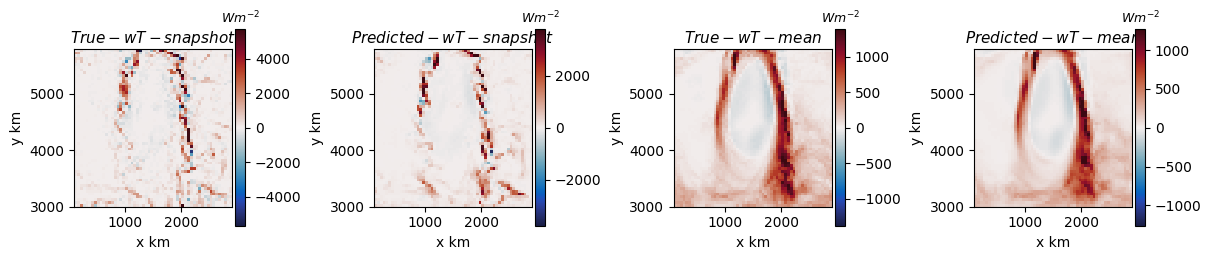

## Test how mean R2 change with averaging time windows

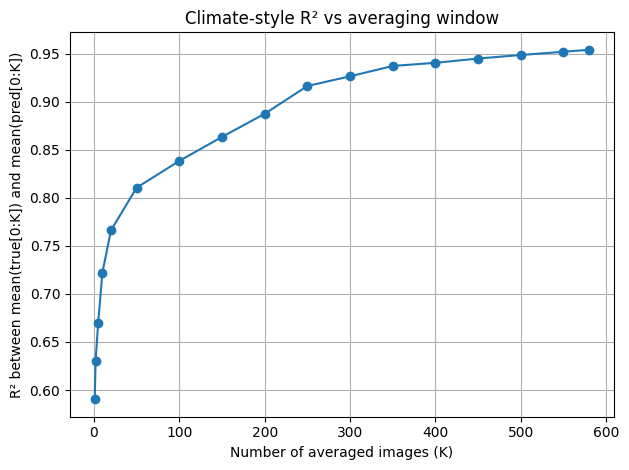

Ks: [1, 2, 5, 10, 20, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 580]
R2: [0.5904450814914854, 0.6305228724618486, 0.669854420774839, 0.7222616879153387, 0.7660526390248649, 0.8104621284522058, 0.8383085933980815, 0.86328826018835, 0.8873076331614858, 0.9162186163281947, 0.9263346462541746, 0.9370662951139626, 0.9403790911611382, 0.9448250414562455, 0.9484983960211363, 0.9518802083241964, 0.9538993660214587]


In [12]:


import numpy as np
import matplotlib.pyplot as plt
import torch

def r2_image(y_true, y_pred, eps: float = 1e-12) -> float:
    yt = np.asarray(y_true, dtype=np.float64).ravel()
    yp = np.asarray(y_pred, dtype=np.float64).ravel()
    if yt.shape != yp.shape:
        raise ValueError(f"Shape mismatch: {y_true.shape} vs {y_pred.shape}")
    yt_mean = yt.mean()
    ss_tot = np.sum((yt - yt_mean) ** 2)
    if ss_tot <= eps:
        return float("nan")
    ss_res = np.sum((yt - yp) ** 2)
    return float(1.0 - ss_res / ss_tot)

# ---------------- load preds/true ----------------
y_true_path = "../../../outputs/cfg_9/test_y_true.npy"
y_pred_path = "../../../outputs/cfg_9/test_y_pred.npy"
y_true = np.load(y_true_path)   # (N,1,H,W)
y_pred = np.load(y_pred_path)   # (N,1,H,W)

N = y_true.shape[0]
assert y_pred.shape == y_true.shape

# ---------------- OPTIONAL: de-normalize ----------------
# Set this to False if you saved with denorm_y=True already.
APPLY_DENORM = False

if APPLY_DENORM:
    ckpt_path = "../../../check_point/cfg_9/best_unet_conv.pt"
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    norm = ckpt["norm"]
    y_mu = float(norm["y_mu"])
    y_sd = float(norm["y_sd"])
    y_true = y_true * y_sd + y_mu
    y_pred = y_pred * y_sd + y_mu

# ---------------- build K list ----------------
Ks = [1, 2, 5, 10, 20, 50, 100]
Ks += list(range(150, 581, 50))     # 150,200,...,550,600
Ks += [580]
Ks = sorted(set([k for k in Ks if 1 <= k <= N]))  # keep valid, unique, sorted

# ---------------- efficient running mean via cumulative sum ----------------
# work with (N,H,W)
yt = y_true[:, 0].astype(np.float64)   # (N,H,W)
yp = y_pred[:, 0].astype(np.float64)

cumsum_true = np.cumsum(yt, axis=0)    # (N,H,W)
cumsum_pred = np.cumsum(yp, axis=0)

r2s = []
for k in Ks:
    true_mean_map = cumsum_true[k-1] / k
    pred_mean_map = cumsum_pred[k-1] / k
    r2s.append(r2_image(true_mean_map, pred_mean_map))

# ---------------- plot ----------------
plt.figure()
plt.plot(Ks, r2s, marker="o")
plt.xlabel("Number of averaged images (K)")
plt.ylabel("R² between mean(true[0:K]) and mean(pred[0:K])")
plt.title("Climate-style R² vs averaging window")
plt.grid(True)
plt.tight_layout()
plt.savefig("r2_vs_K.png", dpi=200)
plt.show()

print("Ks:", Ks)
print("R2:", r2s)

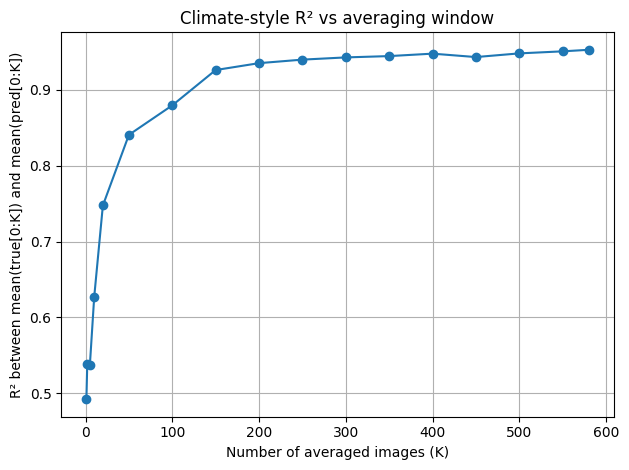

Ks: [1, 2, 5, 10, 20, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 580]
R2: [0.4920600780819733, 0.5381613298261363, 0.5369250572661313, 0.6268256315728795, 0.7474901755642007, 0.8406212571667678, 0.8794886666149402, 0.9260502856977767, 0.9351271052278497, 0.9397687814276388, 0.9426989426711617, 0.9444333514033765, 0.9476488710684517, 0.9431583184418183, 0.9480035245484368, 0.9507030249052811, 0.952721715791413]


In [13]:


import numpy as np
import matplotlib.pyplot as plt
import torch

def r2_image(y_true, y_pred, eps: float = 1e-12) -> float:
    yt = np.asarray(y_true, dtype=np.float64).ravel()
    yp = np.asarray(y_pred, dtype=np.float64).ravel()
    if yt.shape != yp.shape:
        raise ValueError(f"Shape mismatch: {y_true.shape} vs {y_pred.shape}")
    yt_mean = yt.mean()
    ss_tot = np.sum((yt - yt_mean) ** 2)
    if ss_tot <= eps:
        return float("nan")
    ss_res = np.sum((yt - yp) ** 2)
    return float(1.0 - ss_res / ss_tot)

# ---------------- load preds/true ----------------
y_true_path = "../../../outputs/cfg_2/test_y_true.npy"
y_pred_path = "../../../outputs/cfg_2/test_y_pred.npy"
y_true = np.load(y_true_path)   # (N,1,H,W)
y_pred = np.load(y_pred_path)   # (N,1,H,W)

N = y_true.shape[0]
assert y_pred.shape == y_true.shape

# ---------------- OPTIONAL: de-normalize ----------------
# Set this to False if you saved with denorm_y=True already.
APPLY_DENORM = False

if APPLY_DENORM:
    ckpt_path = "../../../check_point/cfg_2/best_unet_conv.pt"
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    norm = ckpt["norm"]
    y_mu = float(norm["y_mu"])
    y_sd = float(norm["y_sd"])
    y_true = y_true * y_sd + y_mu
    y_pred = y_pred * y_sd + y_mu

# ---------------- build K list ----------------
Ks = [1, 2, 5, 10, 20, 50, 100]
Ks += list(range(150, 581, 50))     # 150,200,...,550,600
Ks += [580]
Ks = sorted(set([k for k in Ks if 1 <= k <= N]))  # keep valid, unique, sorted

# ---------------- efficient running mean via cumulative sum ----------------
# work with (N,H,W)
yt = y_true[:, 0].astype(np.float64)   # (N,H,W)
yp = y_pred[:, 0].astype(np.float64)

cumsum_true = np.cumsum(yt, axis=0)    # (N,H,W)
cumsum_pred = np.cumsum(yp, axis=0)

r2s = []
for k in Ks:
    true_mean_map = cumsum_true[k-1] / k
    pred_mean_map = cumsum_pred[k-1] / k
    r2s.append(r2_image(true_mean_map, pred_mean_map))

# ---------------- plot ----------------
plt.figure()
plt.plot(Ks, r2s, marker="o")
plt.xlabel("Number of averaged images (K)")
plt.ylabel("R² between mean(true[0:K]) and mean(pred[0:K])")
plt.title("Climate-style R² vs averaging window")
plt.grid(True)
plt.tight_layout()
plt.savefig("r2_vs_K.png", dpi=200)
plt.show()

print("Ks:", Ks)
print("R2:", r2s)

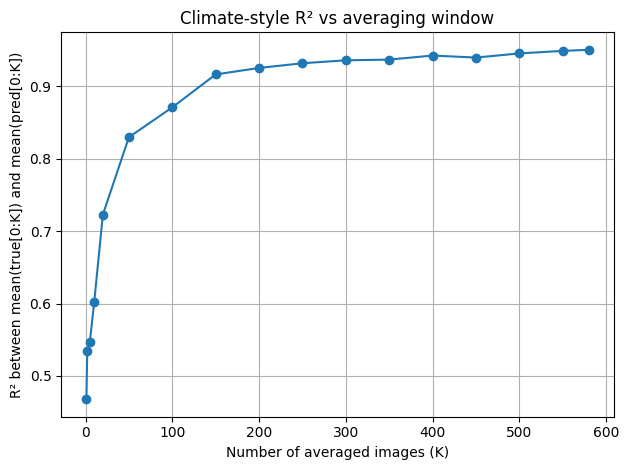

Ks: [1, 2, 5, 10, 20, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 580]
R2: [0.4676857623377191, 0.5347950851091989, 0.5472701204883754, 0.6018253737639381, 0.7228646230409543, 0.8298642607284803, 0.8711264599657006, 0.9166447231320997, 0.9255959587084106, 0.9321020314474346, 0.9361692948262772, 0.9371315439438221, 0.9427672775725394, 0.9399560860674753, 0.9456995810421548, 0.9491918911502392, 0.950690741304092]


In [14]:


import numpy as np
import matplotlib.pyplot as plt
import torch

def r2_image(y_true, y_pred, eps: float = 1e-12) -> float:
    yt = np.asarray(y_true, dtype=np.float64).ravel()
    yp = np.asarray(y_pred, dtype=np.float64).ravel()
    if yt.shape != yp.shape:
        raise ValueError(f"Shape mismatch: {y_true.shape} vs {y_pred.shape}")
    yt_mean = yt.mean()
    ss_tot = np.sum((yt - yt_mean) ** 2)
    if ss_tot <= eps:
        return float("nan")
    ss_res = np.sum((yt - yp) ** 2)
    return float(1.0 - ss_res / ss_tot)

# ---------------- load preds/true ----------------
y_true_path = "../../../outputs/cfg_1/test_y_true.npy"
y_pred_path = "../../../outputs/cfg_1/test_y_pred.npy"
y_true = np.load(y_true_path)   # (N,1,H,W)
y_pred = np.load(y_pred_path)   # (N,1,H,W)

N = y_true.shape[0]
assert y_pred.shape == y_true.shape

# ---------------- OPTIONAL: de-normalize ----------------
# Set this to False if you saved with denorm_y=True already.
APPLY_DENORM = False

if APPLY_DENORM:
    ckpt_path = "../../../check_point/cfg_1/best_unet_conv.pt"
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    norm = ckpt["norm"]
    y_mu = float(norm["y_mu"])
    y_sd = float(norm["y_sd"])
    y_true = y_true * y_sd + y_mu
    y_pred = y_pred * y_sd + y_mu

# ---------------- build K list ----------------
Ks = [1, 2, 5, 10, 20, 50, 100]
Ks += list(range(150, 581, 50))     # 150,200,...,550,600
Ks += [580]
Ks = sorted(set([k for k in Ks if 1 <= k <= N]))  # keep valid, unique, sorted

# ---------------- efficient running mean via cumulative sum ----------------
# work with (N,H,W)
yt = y_true[:, 0].astype(np.float64)   # (N,H,W)
yp = y_pred[:, 0].astype(np.float64)

cumsum_true = np.cumsum(yt, axis=0)    # (N,H,W)
cumsum_pred = np.cumsum(yp, axis=0)

r2s = []
for k in Ks:
    true_mean_map = cumsum_true[k-1] / k
    pred_mean_map = cumsum_pred[k-1] / k
    r2s.append(r2_image(true_mean_map, pred_mean_map))

# ---------------- plot ----------------
plt.figure()
plt.plot(Ks, r2s, marker="o")
plt.xlabel("Number of averaged images (K)")
plt.ylabel("R² between mean(true[0:K]) and mean(pred[0:K])")
plt.title("Climate-style R² vs averaging window")
plt.grid(True)
plt.tight_layout()
plt.savefig("r2_vs_K.png", dpi=200)
plt.show()

print("Ks:", Ks)
print("R2:", r2s)

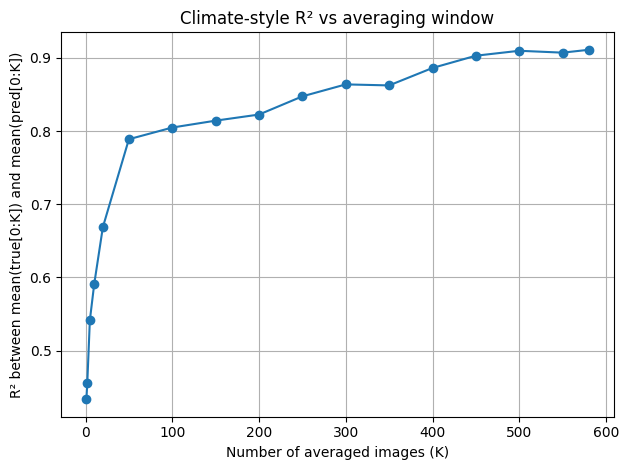

Ks: [1, 2, 5, 10, 20, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 580]
R2: [0.43352544547986527, 0.45516372111083814, 0.5415635660466589, 0.590847973760987, 0.6688391905614867, 0.7889814643206657, 0.8049382352470158, 0.8143571732771349, 0.822693722210931, 0.8475845303629604, 0.8639160033348534, 0.8625206532468431, 0.8863690630597291, 0.9031278438838755, 0.9098736023159484, 0.9073019081570345, 0.9111952530323266]


In [15]:


import numpy as np
import matplotlib.pyplot as plt
import torch

def r2_image(y_true, y_pred, eps: float = 1e-12) -> float:
    yt = np.asarray(y_true, dtype=np.float64).ravel()
    yp = np.asarray(y_pred, dtype=np.float64).ravel()
    if yt.shape != yp.shape:
        raise ValueError(f"Shape mismatch: {y_true.shape} vs {y_pred.shape}")
    yt_mean = yt.mean()
    ss_tot = np.sum((yt - yt_mean) ** 2)
    if ss_tot <= eps:
        return float("nan")
    ss_res = np.sum((yt - yp) ** 2)
    return float(1.0 - ss_res / ss_tot)

# ---------------- load preds/true ----------------
y_true_path = "../../../outputs/cfg_5/test_y_true.npy"
y_pred_path = "../../../outputs/cfg_5/test_y_pred.npy"
y_true = np.load(y_true_path)   # (N,1,H,W)
y_pred = np.load(y_pred_path)   # (N,1,H,W)

N = y_true.shape[0]
assert y_pred.shape == y_true.shape

# ---------------- OPTIONAL: de-normalize ----------------
# Set this to False if you saved with denorm_y=True already.
APPLY_DENORM = False

if APPLY_DENORM:
    ckpt_path = "../../../check_point/cfg_5/best_unet_conv.pt"
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    norm = ckpt["norm"]
    y_mu = float(norm["y_mu"])
    y_sd = float(norm["y_sd"])
    y_true = y_true * y_sd + y_mu
    y_pred = y_pred * y_sd + y_mu

# ---------------- build K list ----------------
Ks = [1, 2, 5, 10, 20, 50, 100]
Ks += list(range(150, 581, 50))     # 150,200,...,550,600
Ks += [580]
Ks = sorted(set([k for k in Ks if 1 <= k <= N]))  # keep valid, unique, sorted

# ---------------- efficient running mean via cumulative sum ----------------
# work with (N,H,W)
yt = y_true[:, 0].astype(np.float64)   # (N,H,W)
yp = y_pred[:, 0].astype(np.float64)

cumsum_true = np.cumsum(yt, axis=0)    # (N,H,W)
cumsum_pred = np.cumsum(yp, axis=0)

r2s = []
for k in Ks:
    true_mean_map = cumsum_true[k-1] / k
    pred_mean_map = cumsum_pred[k-1] / k
    r2s.append(r2_image(true_mean_map, pred_mean_map))

# ---------------- plot ----------------
plt.figure()
plt.plot(Ks, r2s, marker="o")
plt.xlabel("Number of averaged images (K)")
plt.ylabel("R² between mean(true[0:K]) and mean(pred[0:K])")
plt.title("Climate-style R² vs averaging window")
plt.grid(True)
plt.tight_layout()
plt.savefig("r2_vs_K.png", dpi=200)
plt.show()

print("Ks:", Ks)
print("R2:", r2s)

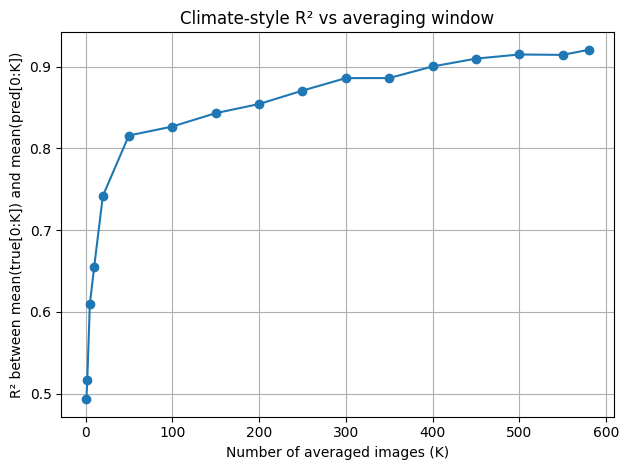

Ks: [1, 2, 5, 10, 20, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 580]
R2: [0.49324194003459987, 0.5166096507061726, 0.6098578911398476, 0.6552771227196028, 0.7419377912869072, 0.8156915361957259, 0.8266397860477772, 0.8430220967515717, 0.8541547971608309, 0.8705516048278176, 0.8858613328321386, 0.8859315678744075, 0.9000709290108171, 0.9096879157119357, 0.9147359910900675, 0.9142795433185582, 0.9204705440749943]


In [16]:


import numpy as np
import matplotlib.pyplot as plt
import torch

def r2_image(y_true, y_pred, eps: float = 1e-12) -> float:
    yt = np.asarray(y_true, dtype=np.float64).ravel()
    yp = np.asarray(y_pred, dtype=np.float64).ravel()
    if yt.shape != yp.shape:
        raise ValueError(f"Shape mismatch: {y_true.shape} vs {y_pred.shape}")
    yt_mean = yt.mean()
    ss_tot = np.sum((yt - yt_mean) ** 2)
    if ss_tot <= eps:
        return float("nan")
    ss_res = np.sum((yt - yp) ** 2)
    return float(1.0 - ss_res / ss_tot)

# ---------------- load preds/true ----------------
y_true_path = "../../../outputs/cfg_7/test_y_true.npy"
y_pred_path = "../../../outputs/cfg_7/test_y_pred.npy"
y_true = np.load(y_true_path)   # (N,1,H,W)
y_pred = np.load(y_pred_path)   # (N,1,H,W)

N = y_true.shape[0]
assert y_pred.shape == y_true.shape

# ---------------- OPTIONAL: de-normalize ----------------
# Set this to False if you saved with denorm_y=True already.
APPLY_DENORM = False

if APPLY_DENORM:
    ckpt_path = "../../../check_point/cfg_7/best_unet_conv.pt"
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    norm = ckpt["norm"]
    y_mu = float(norm["y_mu"])
    y_sd = float(norm["y_sd"])
    y_true = y_true * y_sd + y_mu
    y_pred = y_pred * y_sd + y_mu

# ---------------- build K list ----------------
Ks = [1, 2, 5, 10, 20, 50, 100]
Ks += list(range(150, 581, 50))     # 150,200,...,550,600
Ks += [580]
Ks = sorted(set([k for k in Ks if 1 <= k <= N]))  # keep valid, unique, sorted

# ---------------- efficient running mean via cumulative sum ----------------
# work with (N,H,W)
yt = y_true[:, 0].astype(np.float64)   # (N,H,W)
yp = y_pred[:, 0].astype(np.float64)

cumsum_true = np.cumsum(yt, axis=0)    # (N,H,W)
cumsum_pred = np.cumsum(yp, axis=0)

r2s = []
for k in Ks:
    true_mean_map = cumsum_true[k-1] / k
    pred_mean_map = cumsum_pred[k-1] / k
    r2s.append(r2_image(true_mean_map, pred_mean_map))

# ---------------- plot ----------------
plt.figure()
plt.plot(Ks, r2s, marker="o")
plt.xlabel("Number of averaged images (K)")
plt.ylabel("R² between mean(true[0:K]) and mean(pred[0:K])")
plt.title("Climate-style R² vs averaging window")
plt.grid(True)
plt.tight_layout()
plt.savefig("r2_vs_K.png", dpi=200)
plt.show()

print("Ks:", Ks)
print("R2:", r2s)

## How R2 change with time in test data

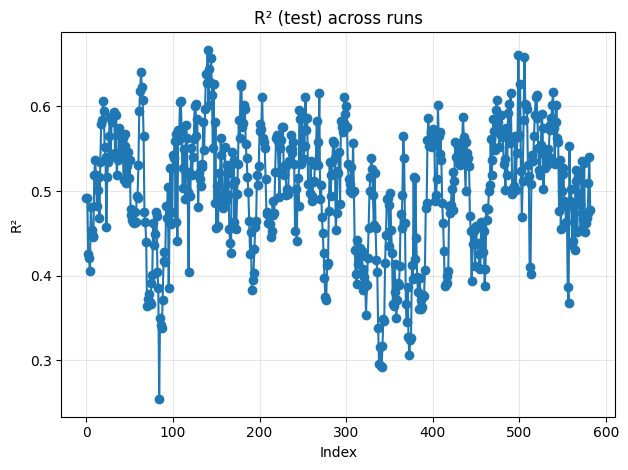

In [14]:
import json
from pathlib import Path

import matplotlib.pyplot as plt


def load_r2_list(json_path: str | Path, key: str | None = None) -> list[float]:
    """
    Load R2 values from a JSON file.

    Supports:
      1) A JSON list:            [0.51, 0.53, 0.49, ...]
      2) A JSON dict with key:   {"r2": [0.51, 0.53, ...]}  (set key="r2")
      3) A JSON dict of values:  {"run1": 0.51, "run2": 0.53, ...} (key=None)
    """
    json_path = Path(json_path)
    with json_path.open("r") as f:
        obj = json.load(f)

    if isinstance(obj, list):
        r2 = obj
    elif isinstance(obj, dict):
        if key is not None:
            if key not in obj:
                raise KeyError(f"Key '{key}' not found. Available keys: {list(obj.keys())[:20]}")
            r2 = obj[key]
        else:
            # dict of scalar values -> take values in insertion order
            r2 = list(obj.values())
    else:
        raise TypeError(f"Unsupported JSON type: {type(obj)}")

    # Cast to float and validate
    out = []
    for i, v in enumerate(r2):
        try:
            out.append(float(v))
        except Exception as e:
            raise ValueError(f"Could not convert r2[{i}]={v!r} to float") from e

    return out


def plot_r2(r2: list[float], x: list[float] | None = None, title: str = "R² over index"):
    """
    Plot R2 vs index (default) or vs provided x.
    """
    if x is None:
        x = list(range(len(r2)))
        xlabel = "Index"
    else:
        if len(x) != len(r2):
            raise ValueError(f"x and r2 must have same length: {len(x)} vs {len(r2)}")
        xlabel = "x"

    plt.figure()
    plt.plot(x, r2, marker="o")
    plt.xlabel(xlabel)
    plt.ylabel("R²")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# ------------------- Example usage -------------------
r2 = load_r2_list("../../../outputs/cfg_2/test_stats.json", key="image_r2_list")
plot_r2(r2, title="R² (test) across runs")


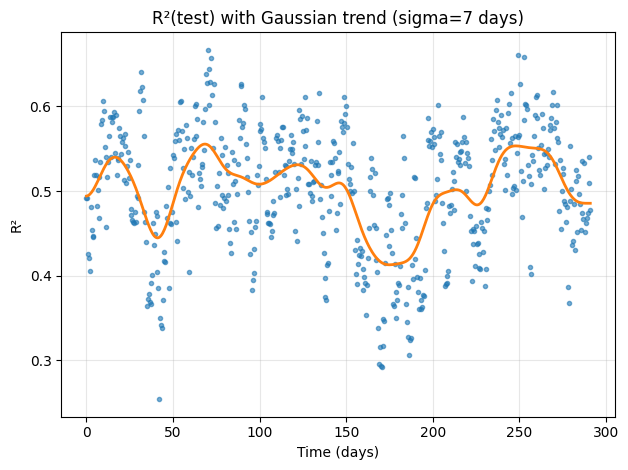

In [16]:
from scipy.ndimage import gaussian_filter1d

sigma_days = 7  # smoothing scale in days
sigma_pts = sigma_days / dt_days
trend_g = gaussian_filter1d(r2, sigma=sigma_pts)

plt.figure()
plt.plot(t_days, r2, marker="o", linestyle="", markersize=3, alpha=0.6)
plt.plot(t_days, trend_g, linewidth=2)
plt.xlabel("Time (days)")
plt.ylabel("R²")
plt.title(f"R²(test) with Gaussian trend (sigma={sigma_days} days)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
import numpy as np

x = r2 - np.mean(r2)
acf = np.correlate(x, x, mode="full")
acf = acf[acf.size // 2:]  # keep nonnegative lags
acf = acf / acf[0]

lags = np.arange(len(acf))
lags_days = lags * dt_days

# e-folding decorrelation time: first lag where ACF < 1/e
target = 1/np.e
idx = np.where(acf < target)[0]
tau_days = lags_days[idx[0]] if len(idx) else np.nan

print(f"e-folding decorrelation time ~ {tau_days:.2f} days")

e-folding decorrelation time ~ 3.00 days


Dominant period ~ 145.75 days (peak frequency 0.0069 cycles/day)


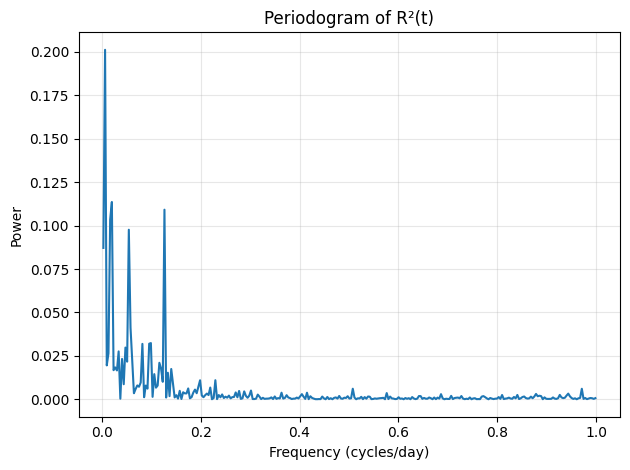

In [19]:
from scipy.signal import periodogram

# detrend (remove mean) so low-freq peak isn’t just the mean
x = r2 - np.mean(r2)

fs = 1.0 / dt_days  # samples per day (2/day for 12h)
freq, power = periodogram(x, fs=fs, scaling="density")

# ignore zero frequency
freq2 = freq[1:]
power2 = power[1:]

# find strongest peak
i_peak = np.argmax(power2)
f_peak = freq2[i_peak]              # cycles per day
period_days = 1.0 / f_peak

print(f"Dominant period ~ {period_days:.2f} days (peak frequency {f_peak:.4f} cycles/day)")
import matplotlib.pyplot as plt

plt.figure()
plt.plot(freq2, power2)
plt.xlabel("Frequency (cycles/day)")
plt.ylabel("Power")
plt.title("Periodogram of R²(t)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

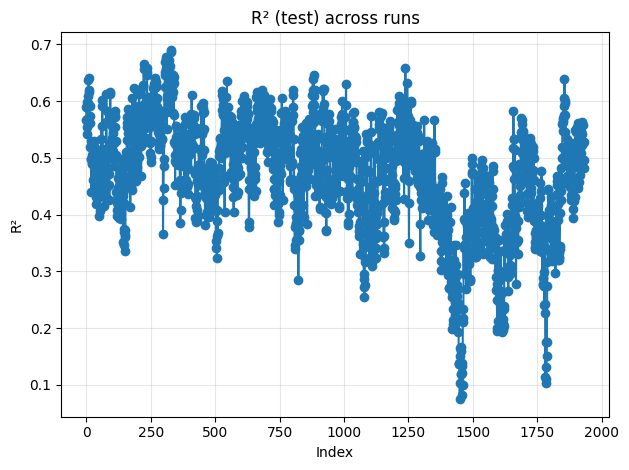

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt


def load_r2_list(json_path: str | Path, key: str | None = None) -> list[float]:
    """
    Load R2 values from a JSON file.

    Supports:
      1) A JSON list:            [0.51, 0.53, 0.49, ...]
      2) A JSON dict with key:   {"r2": [0.51, 0.53, ...]}  (set key="r2")
      3) A JSON dict of values:  {"run1": 0.51, "run2": 0.53, ...} (key=None)
    """
    json_path = Path(json_path)
    with json_path.open("r") as f:
        obj = json.load(f)

    if isinstance(obj, list):
        r2 = obj
    elif isinstance(obj, dict):
        if key is not None:
            if key not in obj:
                raise KeyError(f"Key '{key}' not found. Available keys: {list(obj.keys())[:20]}")
            r2 = obj[key]
        else:
            # dict of scalar values -> take values in insertion order
            r2 = list(obj.values())
    else:
        raise TypeError(f"Unsupported JSON type: {type(obj)}")

    # Cast to float and validate
    out = []
    for i, v in enumerate(r2):
        try:
            out.append(float(v))
        except Exception as e:
            raise ValueError(f"Could not convert r2[{i}]={v!r} to float") from e

    return out


def plot_r2(r2: list[float], x: list[float] | None = None, title: str = "R² over index"):
    """
    Plot R2 vs index (default) or vs provided x.
    """
    if x is None:
        x = list(range(len(r2)))
        xlabel = "Index"
    else:
        if len(x) != len(r2):
            raise ValueError(f"x and r2 must have same length: {len(x)} vs {len(r2)}")
        xlabel = "x"

    plt.figure()
    plt.plot(x, r2, marker="o")
    plt.xlabel(xlabel)
    plt.ylabel("R²")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# ------------------- Example usage -------------------
r2 = load_r2_list("../../../outputs/cfg_9/test_stats.json", key="image_r2_list")
plot_r2(r2, title="R² (test) across runs")


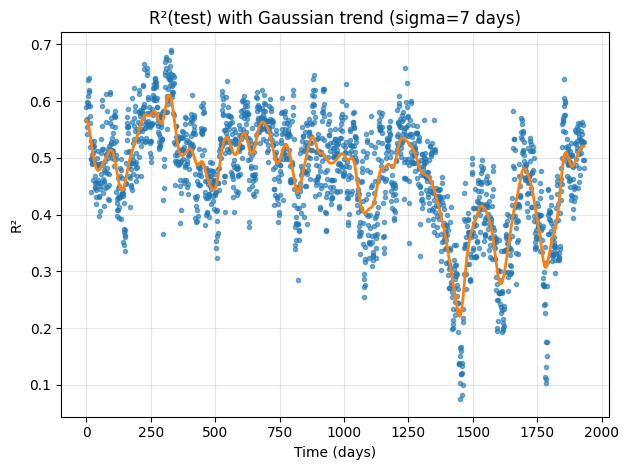

In [10]:
from scipy.ndimage import gaussian_filter1d

sigma_days = 7  # smoothing scale in days
dt_days = 0.5
sigma_pts = sigma_days / dt_days
trend_g = gaussian_filter1d(r2, sigma=sigma_pts)

plt.figure()
plt.plot( r2, marker="o", linestyle="", markersize=3, alpha=0.6)
plt.plot( trend_g, linewidth=2)
plt.xlabel("Time (days)")
plt.ylabel("R²")
plt.title(f"R²(test) with Gaussian trend (sigma={sigma_days} days)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
import numpy as np

x = r2 - np.mean(r2)
acf = np.correlate(x, x, mode="full")
acf = acf[acf.size // 2:]  # keep nonnegative lags
acf = acf / acf[0]

lags = np.arange(len(acf))
lags_days = lags * dt_days

# e-folding decorrelation time: first lag where ACF < 1/e
target = 1/np.e
idx = np.where(acf < target)[0]
tau_days = lags_days[idx[0]] if len(idx) else np.nan

print(f"e-folding decorrelation time ~ {tau_days:.2f} days")

e-folding decorrelation time ~ 26.00 days


# Compare the npz data with data after data_loader

last batch shapes: torch.Size([9, 7, 56, 56]) torch.Size([9, 1, 56, 56])
last sample shapes: torch.Size([7, 56, 56]) torch.Size([1, 56, 56])


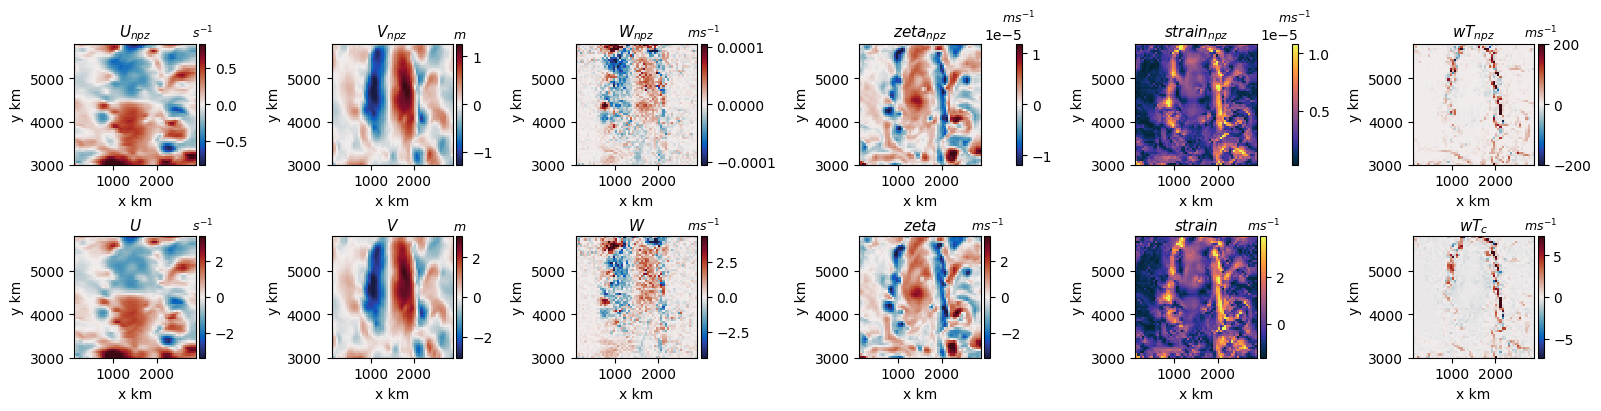

In [10]:
# compare the npz data with data after data_loader

# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import data_loader

from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf
import importlib
from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_MITgcm
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=10, box_i=10)
XC_c = ds_coarse["XC"]
YC_c = ds_coarse["YC"]
X = np.load("/scratch/jczhang/submeso_data_driven/src/data/k12/X.npy")
y = np.load("/scratch/jczhang/submeso_data_driven/src/data/k12/y.npy")
device = None
# data loader
train_loader, val_loader, test_loader, meta = data_loader.prepare_unet_dataloaders(
    X, y,
    batch_size=64,
    num_workers=8,
    seed=42,
    split_mode='time_ordered',            # "time_ordered" or "random"
    frac_train=0.8,
    frac_skip=0.0,
    frac_val=0.1,
    frac_test=0.1,
    normalize_x=True,
    normalize_y=True,
    shuffle_train=False,
    device=device,                    # for pin_memory logic
)

# get last batch
for Xb, yb in test_loader:
    pass  # get the last batch 

# last sample in that last batch
x_last = Xb[-1]   # shape (C, H, W)
y_last = yb[-1]   # shape (1, H, W) 

print("last batch shapes:", Xb.shape, yb.shape)
print("last sample shapes:", x_last.shape, y_last.shape)
    
# limits function
def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# load the npz data
fn = "/scratch/jczhang/submeso_data_driven/data/k12/U.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    U_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/submeso_data_driven/data/k12/V.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    V_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/submeso_data_driven/data/k12/W.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    W_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/submeso_data_driven/data/k12/zeta.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    zeta_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/submeso_data_driven/data/k12/strain.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    strain_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/submeso_data_driven/data/k12/T.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    T_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/submeso_data_driven/data/k12/wT.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)        # (Nt,)
    wT_npz = npz["data"].astype(np.float32)       # (Nt, j, i)

# position
pos = -4
x1, x2 = 60,  116
y1, y2 = 2, 58
dx = 30
# plot 
fields = {
    r"$U_{npz}$":         {"Z": X[pos,0,:,:],  "units": r"$s^{-1}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$V_{npz}$":         {"Z": X[pos,1,:,:],  "units": r"$m$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$W_{npz}$":         {"Z": X[pos,2,:,:],  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$zeta_{npz}$":         {"Z": X[pos,3,:,:],  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$strain_{npz}$":         {"Z": X[pos,4,:,:],  "units": r"$m s^{-1}$",  "kind": "positive", "cmap":cmo.thermal, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_{npz}$":         {"Z": y[pos,0,:,:],  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    
    r"$U$":         {"Z": x_last[0,:,:],  "units": r"$s^{-1}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$V$":         {"Z": x_last[1,:,:],  "units": r"$m$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$W$":         {"Z": x_last[2,:,:],  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$zeta$":         {"Z": x_last[3,:,:],  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$strain$":         {"Z": x_last[4,:,:],  "units": r"$m s^{-1}$",  "kind": "positive", "cmap":cmo.thermal, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT_c$":         {"Z": y_last[0,:,:],  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
}     



# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None

# Plot: 2×5
fig, axes = plt.subplots(2,6, figsize=(16, 4), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    norm = meta["norm"]
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX[:, :], YY[:, :], Z[:, :], shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
fig.savefig("./viz_last_k12.png")
plt.show()

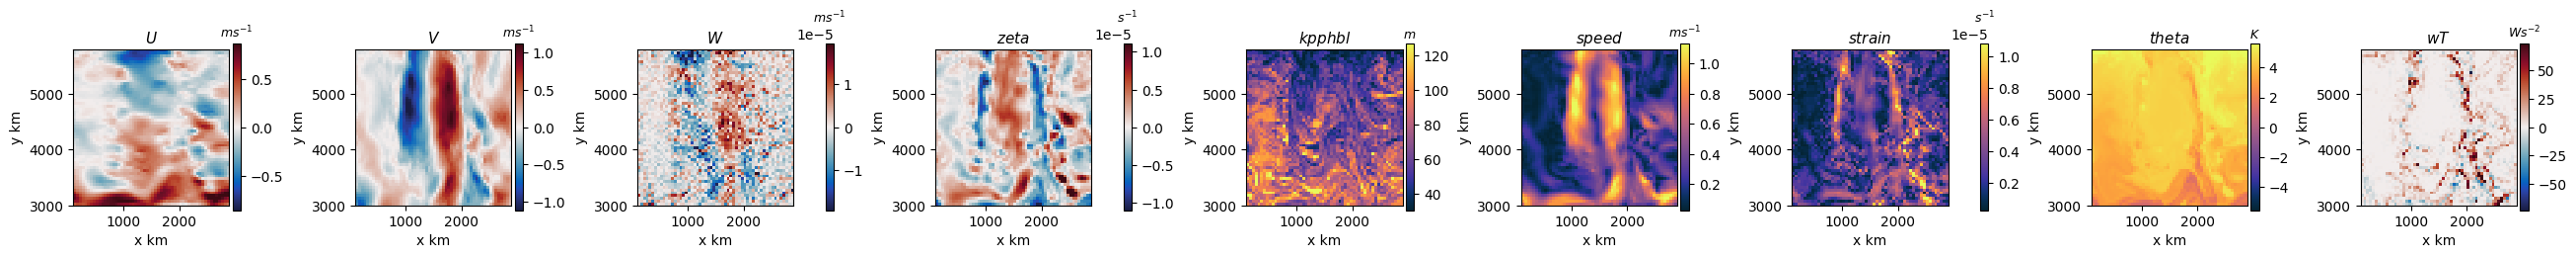

In [10]:
# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid

from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf
import importlib
from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_MITgcm
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=10, box_i=10)
XC_c = ds_coarse["XC"]
YC_c = ds_coarse["YC"]
    
# limits function
def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# load the npz data
fn = "/scratch/jczhang/data_5km/save_coarse/out_npz/U.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    U_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/data_5km/save_coarse/out_npz/V.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    V_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/data_5km/save_coarse/out_npz/W.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    W_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/data_5km/save_coarse/out_npz/zeta.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    zeta_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/data_5km/save_coarse/out_npz/kpphbl.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    kpphbl_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/data_5km/save_coarse/out_npz/speed.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    speed_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/data_5km/save_coarse/out_npz/strain.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    strain_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/data_5km/save_coarse/out_npz/theta.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)   # (Nt,)
    theta_npz = npz["data"].astype(np.float32)       # (Nt, j, i)
fn = "/scratch/jczhang/data_5km/save_coarse/out_npz/wT.npz"
with np.load(fn) as npz:
    t = npz["time_index"].astype(np.int64)        # (Nt,)
    wT_npz = npz["data"].astype(np.float32)       # (Nt, j, i)

# position
pos = 3000
x1, x2 = 60,  116
y1, y2 = 2, 58
dx = 30
# plot 
fields = {
    r"$U$":         {"Z": U_npz[pos,30:86, 1:57],  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$V$":         {"Z": V_npz[pos,30:86, 1:57],  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$W$":         {"Z": W_npz[pos,30:86, 1:57],  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$zeta$":         {"Z": zeta_npz[pos,30:86, 1:57],  "units": r"$s^{-1}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$kpphbl$":         {"Z": kpphbl_npz[pos,30:86, 1:57],  "units": r"$m$",  "kind": "positive", "cmap":cmo.thermal, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$speed$":         {"Z": speed_npz[pos,30:86, 1:57],  "units": r"$m s^{-1}$",  "kind": "positive", "cmap":cmo.thermal, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$strain$":         {"Z": strain_npz[pos,30:86, 1:57],  "units": r"$s^{-1}$",  "kind": "positive", "cmap":cmo.thermal, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$theta$":         {"Z": theta_npz[pos,30:86, 1:57],  "units": r"$K$",  "kind": "signed", "cmap":cmo.thermal, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    r"$wT$":         {"Z": wT_npz[pos,30:86, 1:57],  "units": r"$W s^{-2}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC_c[x1:x2, y1:y2]/1e3, "YC":YC_c[x1:x2, y1:y2]/1e3},
    
}    


# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None

# Plot: 2×5
fig, axes = plt.subplots(1,9, figsize=(26, 2.5), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    norm = meta["norm"]
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX[:, :], YY[:, :], Z[:, :], shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
fig.savefig("./viz_all.png")
plt.show()